# CS 3110/5110: Data Privacy
## Homework 7

In [109]:
# Load the data and libraries
import pandas as pd
import numpy as np
import random
from scipy import stats
import matplotlib.pyplot as plt

def laplace_mech(v, sensitivity, epsilon):
    return v + np.random.laplace(loc=0, scale=sensitivity / epsilon)

def laplace_mech_vec(vec, sensitivity, epsilon):
    return [v + np.random.laplace(loc=0, scale=sensitivity / epsilon) for v in vec]

def gaussian_mech(v, sensitivity, epsilon, delta):
    return v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)

def gaussian_mech_vec(vec, sensitivity, epsilon, delta):
    return [v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)
            for v in vec]

def pct_error(orig, priv):
    return np.abs(orig - priv)/orig * 100.0

adult = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/adult_with_pii.csv')
retail = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/retail.csv').dropna()

## Question 1 (10 points)

Implement the function `adult_hists`, which should return three histograms based on the `adult` dataset:

1. A 1-d histogram of the `Occupation` column
2. A 1-d histogram of the `Education` column
3. A 2-d histogram of the `Race` and `Sex` columns

Your function should have a **total** privacy cost of `epsilon` and a **person-level** unit of privacy.

In [135]:
def adult_hists(epsilon):
    all_hists = [adult.value_counts(["Occupation"]), adult.value_counts(["Education"]), adult.value_counts(["Race", "Sex"])]
    return laplace_mech_vec(all_hists, 1, epsilon / 3)


In [136]:
# TEST CASE
occupation, education, multi = adult_hists(1.0)
assert occupation.sum() > 30000
assert education.sum() > 32000
assert multi.sum() > 32000

## Question 2 (10 points)

Argue that your implementation of `adult_hists` has a total privacy cost of `epsilon` and a person-level unit of privacy.

This function has a total privacy cost of epsilon. laplace_mech_vec uses 1/3 of epsilon on each of the three queries (1/3 * 3 = 1), the sensitivity is 1 for each of the queries because one event = 1 row. Although laplace_mech_vec is being used, some of the useful vector properties don't apply as the three histograms are not disjoint.

This function has a person-level unit of privacy because a neighboring dataset differs by one person (1 person = 1 row).

## Question 3 (10 points)

Implement the function `retail_hist`, which should return one histogram based on the `retail` dataset:

1. A 1-d histogram of the `Country` column

Your function should have a **total** privacy cost of `epsilon` and an **event-level** unit of privacy.

In [112]:
def retail_hist(epsilon):
    cou_hist = retail.value_counts(["Country"])
    return laplace_mech(cou_hist, 1, epsilon)

In [113]:
# TEST CASE
country_hist = retail_hist(1.0)
assert country_hist.sum() > 7400
print(country_hist.head(12))

Country       
United Kingdom    6677.588037
Germany            183.588037
France             157.588037
EIRE               122.588037
Spain               55.588037
Belgium             42.588037
Netherlands         35.588037
Portugal            32.588037
Norway              31.588037
Switzerland         27.588037
Australia           22.588037
Cyprus              15.588037
Name: count, dtype: float64


## Question 3 (10 points)

Argue that your implementation of `retail_hist` has a total privacy cost of `epsilon` and an event-level unit of privacy.

This function has a total privacy cost of epsilon. laplace_mech uses the full epsilon budget to add noise. 

This function has a event-level unit of privacy because a neighboring dataset differs by one transaction. One person can have many transactions (rows), so the sensitivity of 1 may not cover somebody with many transactions.

because this function has an event-level unit of privacy, the sensitivity used for laplace_mech is 1 because one transaction can change the counting query by at most one.

## Question 4 (10 points)

Implement the function `retail_hist_bounded`, which returns a 1-d histogram of the `Country` column, with a total privacy cost of `epsilon`, and with a *user-level* unit of privacy. Use contribution bounding to enforce the unit of privacy.

In [114]:
def retail_hist_bounded(epsilon, k=9):
    bound_retail = retail.groupby("CustomerID").head(k)
    cou_hist = bound_retail.groupby(["Country"]).size()
    return laplace_mech(cou_hist, k, epsilon)

In [115]:
# TEST CASE
country_hist = retail_hist_bounded(1.0)
print(country_hist.sum())
assert country_hist.sum() > 6000

6486.531278621935


## Question 5 (10 points)

Argue that your implementation of `retail_hist_bounded` has a total privacy cost of `epsilon` and a person-level unit of privacy.

This function has a total privacy cost of epsilon. laplace_mech is called once with the full epsilon budget.

This function has a person-level unit of privacy because a neighboring dataset, with one person added or removed, differs by at most k transactions (rows). If bounding was not used, we would either have to set the sensitivity to the number of transactions the person with the most transactons has, requiring us to look at the data (bad), or set the sensitivity to infinity (worse).

Because this function has a person-level unit of privacy bounding each person to k rows, the sensitivity used for the laplace_mech is k.

## Question 6 (20 points)

Implement `retail_avg_quantity`, a function that returns the average quantity of orders in the `retail` dataset, with a total privacy cost of `epsilon` and a person-level unit of privacy.

In [182]:
def retail_avg_quantity(epsilon, k=9, cl=500, noisy = True):
    # Noisy sum / Noisy count
    bound_retail = retail.groupby("CustomerID").head(k)
    bound_retail["Quantity"] = bound_retail["Quantity"].clip(lower=0, upper=cl)

    true_sum = bound_retail["Quantity"].sum()
    true_count = len(bound_retail)

    if not noisy:
        return true_sum / true_count

    sum_sens = k * cl
    count_sens = k

    noisy_sum = laplace_mech(true_sum, sum_sens, epsilon=epsilon/2)
    noisy_count = laplace_mech(true_count, count_sens, epsilon=epsilon/2)
    return noisy_sum / noisy_count



In [176]:
# TEST CASE
avg = retail_avg_quantity(1)
assert avg > 7
assert avg < 13

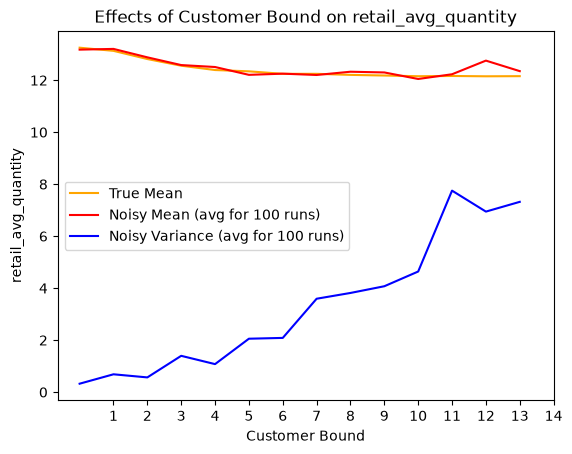

In [192]:
k_upper = 15
num_runs = 100

avgs = []
vars = []
true = []
for n in range(1, k_upper):
    s = pd.Series([retail_avg_quantity(1, k=n) for _ in range(num_runs)])
    avgs.append(s.mean())
    vars.append(s.var())
    true.append(retail_avg_quantity(1, k=n, noisy=False))

plt.plot(true, label="True Mean", color = "orange")
plt.plot(avgs, label=f"Noisy Mean (avg for {num_runs} runs)", color = "red")
plt.plot(vars, label=f"Noisy Variance (avg for {num_runs} runs)", color = "blue")
plt.legend()
plt.xticks(range(1, k_upper, 1))
plt.title("Effects of Customer Bound on retail_avg_quantity")
plt.xlabel(f"Customer Bound")
plt.ylabel("retail_avg_quantity")
plt.show()

![Graph](HW_7_Graph_2.png)

## Question 7 (10 points)

Argue that your implementation of `retail_avg_quantity` has a total privacy cost of `epsilon` and a person-level unit of privacy.

The total privacy cost is epsilon. 

YOUR ANSWER HERE

## Question 8 (10 points)

In 1-3 sentences each, answer the following:

- What impact did the choice of contribution bound have on the average?
- How did you arrive at your choice of contribution bound?
- What is the better choice of privacy unit for the `retail` dataset: event-level or person-level?


- What is an example of a potential negative outcome associated with choosing the event-level unit of privacy for this dataset?
Linkage attack

Privacy does not accumulate, treats each row as independent even though they are not

People self correlate 

Linkage